# Animation

Presets (draw-on, morph, stagger, spin, typewriter), the animation elements underneath them and async
writing, saved as SVG and an animated GIF.

Run it as ``python 09_animation.py`` or open ``09_animation.ipynb``; the SVG animates in the notebook.

In [1]:
import asyncio
import os
import tempfile
from collections.abc import Coroutine
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Any

import svgwriter as svg
from svgwriter.io import write_many_async

`element.animate` adds ready-made SMIL animations and chains. `draw` strokes a ring on like a pen.

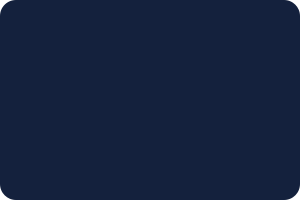

In [2]:
WIDTH, HEIGHT = 300, 200
NAVY, GOLD, CORAL, TEAL = "#14213d", "#fca311", "#ff6b6b", "#2ec4b6"

doc = svg.Document(WIDTH, HEIGHT)
doc.rect(0, 0, WIDTH, HEIGHT, rx=16, fill=NAVY)
ring = doc.circle(80, 90, 52, fill="none", stroke=GOLD, stroke_width=6, stroke_linecap="round")
ring.animate.draw(1.2, begin=0.2)
doc

`morph` turns a `<path>` into any other shape, and `tween` changes any attribute alongside it.

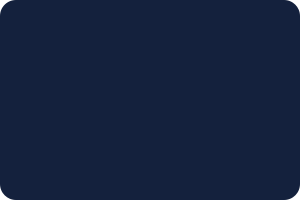

In [3]:
star = svg.Polygon.regular(80, 90, 34, 5, fill=CORAL).to_path()
doc.add(star)
star.animate.fade_in(0.4, begin=0.8).morph(svg.circle(80, 90, 30), 1.0, begin=1.4).tween("fill", CORAL, TEAL, 1.0, begin=1.4)
doc

`stagger` applies a preset to each child of a group, each starting a little after the last.

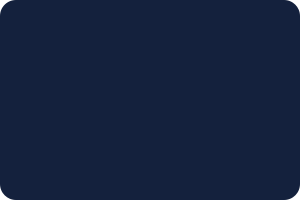

In [4]:
dots = doc.group()
for index, color in enumerate((CORAL, GOLD, TEAL, "#e5e5e5", "#8ecae6")):
    dots.add(svg.circle(160 + index * 28, 60, 10, fill=color))
dots.animate.stagger("fade_in", step=0.2, dur=0.3, begin=0.6).stagger("grow", step=0.2, dur=0.5, begin=0.6)
doc

`spin` turns an element about its centre, repeating forever, and `typewriter` reveals text one character at a time.

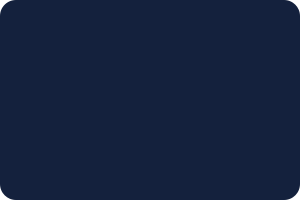

In [5]:
spinner = doc.add(svg.Polygon.regular(244, 122, 16, 4, fill=GOLD))
spinner.animate.fade_in(0.4, begin=1.0).spin(2.4, begin=1.0, repeat="indefinite")
caption = doc.text("svgwriter", x=160, y=170, font_size=26, font_family="Arial, Helvetica, sans-serif", font_weight="bold", fill="white")
caption.animate.typewriter(1.2, begin=1.2)
doc

`doc.at(seconds)` is a still of any moment; here the end of the entrance.

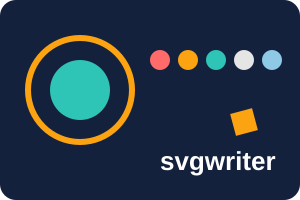

In [6]:
doc.at(3.0)

## Animation elements

Presets build on animation elements, which are children of the shape they animate:
`AnimateTransform.spin` turns a blade, `AnimateMotion` moves a dot along a path, `Animate` pulses its
radius and `Set` hides it after a delay. The function takes the spin period, so several variants can be made.

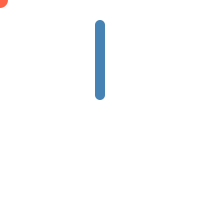

In [7]:
SIZE = 200
VARIANTS = 3


def spinner(speed: float) -> svg.Svg:
    drawing = svg.Document(SIZE, SIZE)
    blade = svg.Rect(95, 20, 10, 80, rx=5, fill="steelblue")
    blade.append(svg.AnimateTransform.spin(100, 100, dur=speed))
    drawing.add(blade)

    track = drawing.define(svg.Path(svg.PathBuilder().circle(100, 100, 70)))
    dot = drawing.add(svg.Circle(0, 0, 8, fill="tomato"))
    dot.append(svg.AnimateMotion(svg.MPath(track), dur=speed * 2, repeat_count=float("inf")))
    dot.append(svg.Animate(attribute_name="r", values=[6, 10, 6], dur=1, repeat_count=float("inf")))
    dot.append(svg.Set("visibility", "hidden", begin=speed * 4, fill=svg.AnimationFill.FREEZE))
    return drawing.root


spinner(1.0)

## Async writing

`write_many_async` writes several documents concurrently. A script starts an event loop with
`asyncio.run`, but Jupyter already runs one, so `run` falls back to a helper thread with its own loop.

In [8]:
def run(coroutine: Coroutine[Any, Any, Any]) -> Any:
    try:
        asyncio.get_running_loop()
    except RuntimeError:
        return asyncio.run(coroutine)
    with ThreadPoolExecutor(1) as pool:
        return pool.submit(asyncio.run, coroutine).result()


async def write_all(out_dir: Path) -> list[Path]:
    targets = {out_dir / f"09_spinner_{i}.svg": spinner(1.0 + i) for i in range(VARIANTS)}
    await write_many_async(targets)
    return list(targets)

Save the animated SVG, a small animated GIF (`fps`, `duration` and `scale` keep it light) and the three
spinners. Set `SVGWRITER_EXAMPLES_OUT` to choose the folder.

In [9]:
out = Path(os.environ.get("SVGWRITER_EXAMPLES_OUT") or tempfile.mkdtemp(prefix="svgwriter-"))
out.mkdir(parents=True, exist_ok=True)
doc.save(out / "09_animation.svg")
doc.save(out / "09_animation.gif", fps=12, duration=3.6)
written = run(write_all(out))
print("saved 09_animation.svg, 09_animation.gif,", ", ".join(path.name for path in written))

saved 09_animation.svg, 09_animation.gif, 09_spinner_0.svg, 09_spinner_1.svg, 09_spinner_2.svg
